# 01 · Inspect the failure data

**Question:** What was recorded, and why might the largest anomaly belong
to a service other than the one where the fault was injected?

We use only the official RCAEval **RE1-OB** metrics subset. All counts below
are recomputed from local files. This notebook does not train a model.

In [1]:
from pathlib import Path
import os
import sys
ROOT = Path.cwd()
if not (ROOT / 'pyproject.toml').is_file():
    ROOT = ROOT.parent
assert (ROOT / 'src/rca').is_dir(), 'Open this notebook from the project folder.'
sys.path.insert(0, str(ROOT / 'src'))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.mplconfig'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from rca.data import list_cases, load_case, service_names
from rca.analysis import configure_plots
np.random.seed(42)
configure_plots()
RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)

## 1. Inspect every recording

We read the case index for labels and inspect each metrics file for its
actual dimensions and timestamps. A candidate prefix is a recorded name;
it is not necessarily a separate architectural microservice.

In [2]:
from rca.analysis import audit_dataset
overview, audit = audit_dataset()
display(pd.DataFrame({
    'Quantity': ['Downloaded cases', 'Evaluable cases', 'Annotated root services',
                 'Distinct candidate prefixes', 'Metrics per case', 'Candidates per case',
                 'Rows per case', 'Missing cells', 'Cases with missing cells'],
    'Observed': [audit['n_cases'], audit['n_evaluable'], len(audit['root_services']),
                 len(audit['candidate_services']), str(audit['metric_count_range']),
                 str(audit['service_count_range']), str(audit['row_count_range']),
                 audit['missing_values'], audit['cases_with_missing_values']]
}))
display(overview.groupby('fault_type').agg(
    cases=('case_id', 'size'), evaluable=('evaluable', 'sum'),
    min_metrics=('n_metrics', 'min'), max_metrics=('n_metrics', 'max'),
    min_rows=('n_timesteps', 'min'), max_rows=('n_timesteps', 'max')
))
print('Annotated roots:', ', '.join(audit['root_services']))
print('Observed metric suffixes:', ', '.join(audit['metric_names']))

,Quantity,Observed
0,Downloaded cases,125
1,Evaluable cases,123
2,Annotated root services,5
3,Distinct candidate prefixes,20
4,Metrics per case,"[49, 59]"
5,Candidates per case,"[13, 19]"
6,Rows per case,"[63, 4201]"
7,Missing cells,5243
8,Cases with missing cells,10


,cases,evaluable,min_metrics,max_metrics,min_rows,max_rows
fault_type,,,,,,
cpu,25,24,49,58,63,4201
delay,25,25,56,58,721,721
disk,25,25,56,58,721,721
loss,25,24,59,59,721,721
mem,25,25,49,49,4201,4201


Annotated roots: adservice, cartservice, checkoutservice, currencyservice, productcatalogservice
Observed metric suffixes: cpu, error, latency, latency-50, latency-90, load, mem, workload


## 2. Check data quality before scoring

Two supplied recordings lack a usable before/after comparison. We preserve
their timestamps and report them. We do not guess where injection occurred.
Missing observations remain NaN: means and standard deviations use the
available values separately within each window. No values are filled from
one side of injection into the other.

In [3]:
display(overview.loc[~overview['evaluable'], [
    'case_id', 'inject_time', 'time_start', 'time_end', 'normal_rows', 'anomalous_rows'
]])
display(overview.loc[overview['missing_values'].gt(0), ['case_id', 'missing_values']])
print('Duplicate timestamps:', audit['duplicate_timestamps'])
print('Infinite values:', audit['infinite_values'])

,case_id,inject_time,time_start,time_end,normal_rows,anomalous_rows
90,re1ob_currencyservice_loss_1,16933142,1693313863,1693314583,0,721
102,re1ob_productcatalogservice_cpu_3,1685373255,1685371737,1685371799,63,0


,case_id,missing_values
4,re1ob_adservice_cpu_5,119
37,re1ob_cartservice_disk_3,421
39,re1ob_cartservice_disk_5,515
53,re1ob_checkoutservice_cpu_4,2987
58,re1ob_checkoutservice_delay_4,425
88,re1ob_currencyservice_disk_4,154
103,re1ob_productcatalogservice_cpu_4,168
110,re1ob_productcatalogservice_disk_1,192
111,re1ob_productcatalogservice_disk_2,182
113,re1ob_productcatalogservice_disk_4,80


Duplicate timestamps: 0
Infinite values: 0


## 3. Open one incident

The loader returns the measurements and label metadata separately. The
ranker receives only the measurements and known injection time. The
two-level columns make it easy to select all measurements for one service.

In [4]:
cases = list_cases()
case_by_id = {case.case_id: case for case in cases}
example = cases[0]
metrics, inject_time, root, fault, system = load_case(example)
print('Case:', example.case_id, '| System:', system, '| Fault:', fault)
print('Annotated root:', root, '| Injection Unix seconds:', inject_time)
print('Measurement shape:', metrics.shape)
display(metrics.xs(root, axis=1, level='service').head())

Case: re1ob_adservice_cpu_1 | System: Online Boutique | Fault: cpu
Annotated root: adservice | Injection Unix seconds: 1685202688
Measurement shape: (4201, 49)


metric,cpu,mem,load,latency
time,,,,
1685200588,44.503283,94769152.0,22.000,0.004832
1685200589,37.376351,94769152.0,66.000,0.004832
1685200590,37.376351,94769152.0,12.065,0.004832
1685200591,37.376351,94769152.0,58.000,0.004854
1685200592,37.376351,94769152.0,62.000,0.004863


## 4. Compare the root with four other candidates

The dashed line is the supplied injection time. We plot CPU, memory, and
an available latency measurement. Comparisons are selected by anomaly
score. Values stay in their raw recorded units; labels do not establish
whether memory is bytes or latency is seconds.

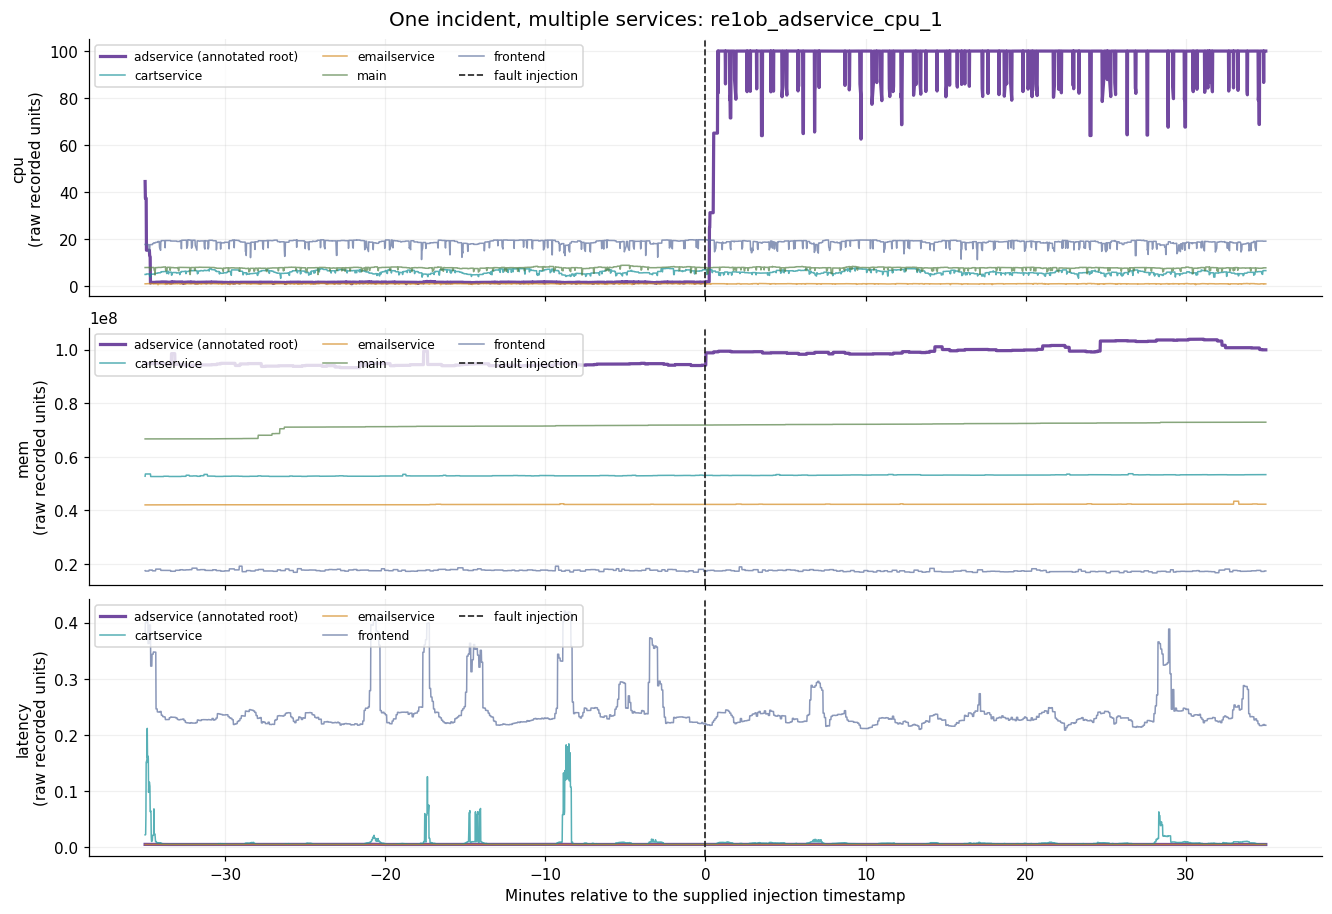

In [5]:
from rca.analysis import plot_case_metrics
fig = plot_case_metrics(example)
plt.show()

## 5. Search all cases for a louder non-root

For every evaluable case, score services first and only then compare with
the annotation. Scores here **ignore metrics that were constant before
injection** (section 6 shows why). Every case where a non-root service
scores strictly higher than the injected root is listed.

The plotted example, `re1ob_productcatalogservice_loss_3`, was **chosen by
hand** from this list: in Online Boutique, `checkoutservice` calls
`productcatalogservice`, so it is the clearest dependency to explain.
A higher score alone does **not** prove the fault caused the caller's
latency rise; that is the hypothesis the project will test.

28 of 123 evaluable cases: a non-root outscores the injected root.


,case_id,fault_type,true_root,root_rank,root_score,root_winning_metric,louder_nonroot,nonroot_score,nonroot_winning_metric,ratio
12,re1ob_checkoutservice_loss_2,loss,checkoutservice,4,7.384446,latency-50,emailservice,667.670297,latency-90,90.415755
11,re1ob_checkoutservice_loss_1,loss,checkoutservice,5,20.336377,mem,paymentservice,377.067535,latency-90,18.541529
25,re1ob_productcatalogservice_loss_3,loss,productcatalogservice,5,14.988639,latency-50,checkoutservice,171.580553,latency-90,11.447374
7,re1ob_cartservice_loss_4,loss,cartservice,2,15.305928,latency-90,productcatalogservice,168.343513,latency-90,10.998583
24,re1ob_productcatalogservice_loss_2,loss,productcatalogservice,5,16.448932,latency-50,checkoutservice,151.145115,latency-90,9.188750
16,re1ob_checkoutservice_mem_1,mem,checkoutservice,2,1039.380041,mem,emailservice,9066.070313,latency,8.722575
27,re1ob_productcatalogservice_loss_5,loss,productcatalogservice,5,11.511242,latency-50,checkoutservice,90.902186,latency-90,7.896818
26,re1ob_productcatalogservice_loss_4,loss,productcatalogservice,5,30.426529,latency-50,checkoutservice,189.071177,latency-90,6.214024


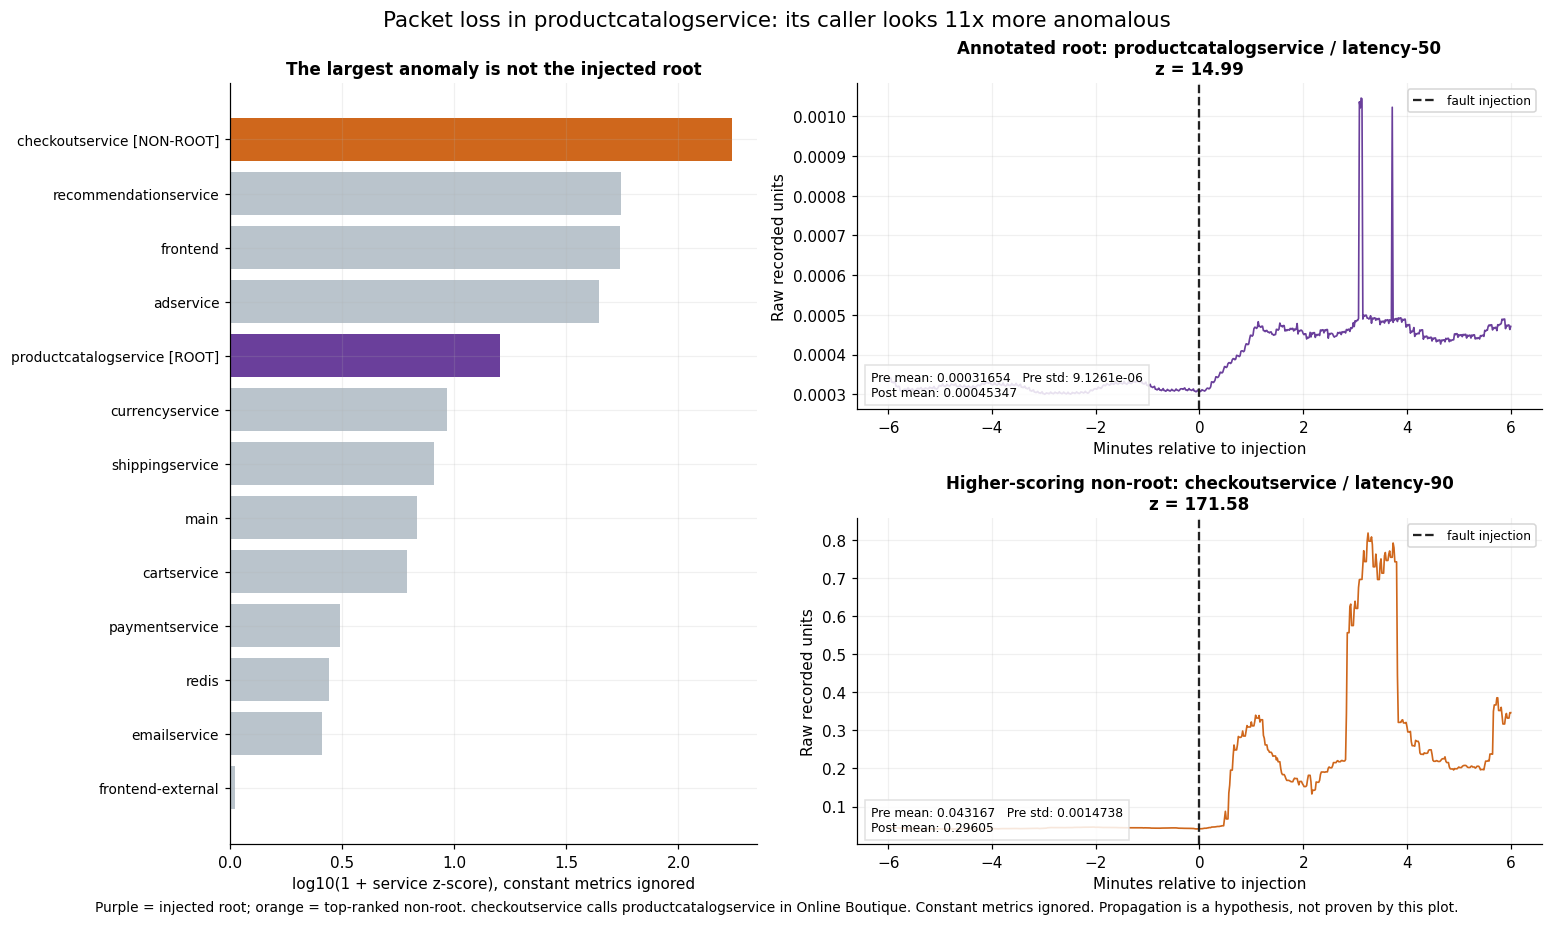

In [6]:
from rca.analysis import find_louder_cases, plot_louder_case
hits = find_louder_cases(skip_constant=True)
print(f'{len(hits)} of {audit["n_evaluable"]} evaluable cases: a non-root outscores the injected root.')
display(hits.sort_values('ratio', ascending=False).head(8))
EXAMPLE = 're1ob_productcatalogservice_loss_3'
assert EXAMPLE in set(hits['case_id']), 'The chosen example is no longer a non-root win.'
fig = plot_louder_case(
    case_by_id[EXAMPLE], skip_constant=True,
    title='Packet loss in productcatalogservice: its caller looks 11x more anomalous',
    caption=('Purple = injected root; orange = top-ranked non-root. checkoutservice calls productcatalogservice in Online Boutique. '
             'Constant metrics ignored. Propagation is a hypothesis, not proven by this plot.'),
    selection_rule='hand-picked from victim_search_zscore_nonconst.csv: clearest documented caller -> callee dependency')
plt.show()

## 6. Why constant metrics must be ignored

The first baseline divides by the normal-window standard deviation plus
$10^{-8}$. When a metric never moved before injection (for example an error
counter stuck at 0), any later blip is divided by $10^{-8}$ and dwarfs a real
CPU spike. Re-running the search **with** constant metrics shows how often
this happens, and the first such case shows the artifact directly.

With constant metrics kept: 61 non-root wins (vs 28 when they are ignored).


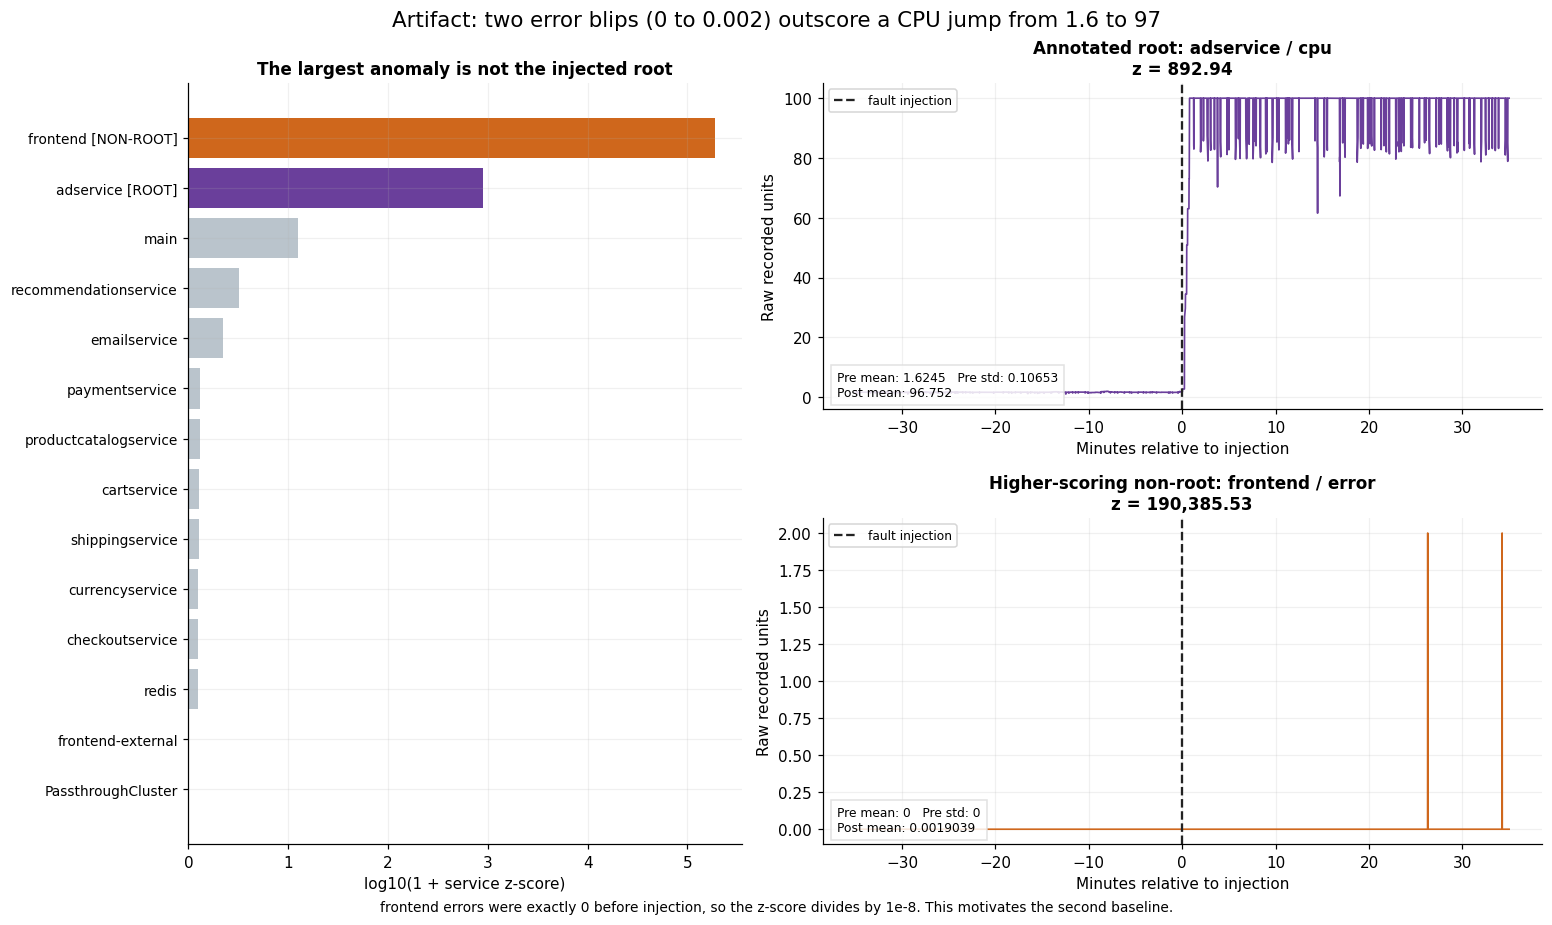

In [7]:
artifact_hits = find_louder_cases(skip_constant=False)
print(f'With constant metrics kept: {len(artifact_hits)} non-root wins '
      f'(vs {len(hits)} when they are ignored).')
fig = plot_louder_case(
    case_by_id[artifact_hits.sort_values('case_id').iloc[0]['case_id']],
    output=RESULTS / 'fig_zero_variance_artifact.png', skip_constant=False,
    title='Artifact: two error blips (0 to 0.002) outscore a CPU jump from 1.6 to 97',
    caption='frontend errors were exactly 0 before injection, so the z-score divides by 1e-8. This motivates the second baseline.',
    selection_rule='first case_id alphabetically among non-root wins with constant metrics kept')
plt.show()

## 7. What we learned

A large anomaly is not automatically the root cause. Ignoring constant
metrics removes a scaling artifact, but non-root services still outscore
the injected root in many packet-loss cases, where callers show the
symptoms. That remaining gap is what a dependency-aware learned model must
close, and it must be compared against this stronger statistical baseline.

Outputs in `results/`: `dataset_overview.csv`, `dataset_audit.json`,
`victim_search_zscore_nonconst.csv`, `victim_search_zscore.csv`,
`fig_case_metrics.png`, `fig_victim_louder_than_culprit.png`,
`fig_zero_variance_artifact.png`.

Source: [official RCAEval dataset](https://huggingface.co/datasets/phamquiluan/RCAEval).